In [6]:
# %% Cell 1: imports
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Experiment settings (inhe badal kar try karein)
UNFREEZE_BLOCKS = 3      # 5 karke bhi try karein
PHASE1_EPOCHS = 15
PHASE2_EPOCHS = 25
LABEL_SMOOTHING = 0.1

# %% Cell 2: data (Drive mount wala cell apna hi rakhein)
data_dir = '/content/drive/MyDrive/breast_cancer/dataset'

IMG = 224
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

train_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    norm,
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.ToTensor(),
    norm,
])

train_base = datasets.ImageFolder(data_dir, transform=train_tf)
eval_base = datasets.ImageFolder(data_dir, transform=eval_tf)
print("Classes:", train_base.class_to_idx)

targets = np.array(train_base.targets)
idx = np.arange(len(targets))

# Stratified 70 / 15 / 15
train_idx, temp_idx = train_test_split(
    idx, test_size=0.30, stratify=targets, random_state=42)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, stratify=targets[temp_idx], random_state=42)

train_loader = DataLoader(Subset(train_base, train_idx), batch_size=32,
                          shuffle=True, num_workers=2)
val_loader = DataLoader(Subset(eval_base, val_idx), batch_size=32,
                        shuffle=False, num_workers=2)
test_loader = DataLoader(Subset(eval_base, test_idx), batch_size=32,
                         shuffle=False, num_workers=2)
print(len(train_idx), len(val_idx), len(test_idx))

counts = np.bincount(targets[train_idx], minlength=3)
weights = len(train_idx) / (3 * counts)
class_weights = torch.tensor(weights, dtype=torch.float32).to(device)
print("Class counts:", counts, "Weights:", weights)

# %% Cell 3: model + losses
class BreastUltrasoundModel(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.base_model = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT)
        for p in self.base_model.parameters():
            p.requires_grad = False
        self.base_model.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.base_model(x)

    def unfreeze_last_blocks(self, n=3):
        for p in self.base_model.features[-n:].parameters():
            p.requires_grad = True


model = BreastUltrasoundModel().to(device)

# Training loss: label smoothing ke saath
train_criterion = nn.CrossEntropyLoss(
    weight=class_weights, label_smoothing=LABEL_SMOOTHING)
# Validation loss: smoothing ke bagair (best model chunne ke liye saaf number)
eval_criterion = nn.CrossEntropyLoss(weight=class_weights)

# %% Cell 4: helper functions
def evaluate(loader, tta=False):
    """tta=True: image aur uski horizontal flip ke probabilities ka average."""
    model.eval()
    all_labels, all_preds, all_probs = [], [], []
    loss_sum = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += eval_criterion(out, y).item() * y.size(0)
            probs = torch.softmax(out, dim=1)
            if tta:
                out_flip = model(torch.flip(x, dims=[3]))
                probs = (probs + torch.softmax(out_flip, dim=1)) / 2
            all_probs.append(probs.cpu().numpy())
            all_preds.extend(probs.argmax(1).cpu().numpy())
            all_labels.extend(y.cpu().numpy())
    n = len(all_labels)
    acc = 100 * np.mean(np.array(all_preds) == np.array(all_labels))
    return (loss_sum / n, acc, np.array(all_labels),
            np.array(all_preds), np.concatenate(all_probs))


def run_phase(optimizer, epochs, name, scheduler=None):
    best_loss, best_acc, best_state = 1e9, 0, None
    for epoch in range(1, epochs + 1):
        model.train()
        run_loss, correct, total = 0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = train_criterion(out, y)
            loss.backward()
            optimizer.step()
            run_loss += loss.item()
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
        if scheduler is not None:
            scheduler.step()
        v_loss, v_acc, *_ = evaluate(val_loader)
        lr_now = optimizer.param_groups[0]['lr']
        print(f"[{name}] Epoch {epoch}/{epochs} | LR {lr_now:.6f} | "
              f"Train loss {run_loss/len(train_loader):.4f} "
              f"acc {100*correct/total:.1f}% | "
              f"Val loss {v_loss:.4f} acc {v_acc:.1f}%")
        # Best model VAL LOSS se chuna jata hai
        if v_loss < best_loss:
            best_loss, best_acc = v_loss, v_acc
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    print(f"[{name}] Best val loss: {best_loss:.4f} (val acc {best_acc:.1f}%)")

# %% Cell 5: Phase 1 - sirf head train (base frozen)
opt1 = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad], lr=1e-3)
run_phase(opt1, epochs=PHASE1_EPOCHS, name="Phase1-head")

# %% Cell 6: Phase 2 - aakhri blocks unfreeze + cosine LR
model.unfreeze_last_blocks(UNFREEZE_BLOCKS)
opt2 = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad], lr=1e-4)
sched2 = torch.optim.lr_scheduler.CosineAnnealingLR(
    opt2, T_max=PHASE2_EPOCHS, eta_min=1e-6)
run_phase(opt2, epochs=PHASE2_EPOCHS, name="Phase2-finetune", scheduler=sched2)

# %% Cell 7: final test evaluation (sirf aakhir mein, ek baar)
names = list(train_base.class_to_idx.keys())

for use_tta in (False, True):
    _, test_acc, y_true, y_pred, y_prob = evaluate(test_loader, tta=use_tta)
    print("=" * 60)
    print(f"TEST {'WITH TTA' if use_tta else 'NO TTA'} | accuracy: {test_acc:.2f}%")
    print(classification_report(y_true, y_pred, target_names=names, digits=3))
    print("Confusion matrix:\n", confusion_matrix(y_true, y_pred))
    print("AUC (OvR):", roc_auc_score(y_true, y_prob, multi_class="ovr"))

#torch.save(model.state_dict(), "busi_efficientnet_b0_v2.pt")
print("Saved: busi_efficientnet_b0_v2.pt")

Device: cuda
Classes: {'benign': 0, 'malignant': 1, 'normal': 2}
546 117 117
Class counts: [306 147  93] Weights: [0.59477124 1.23809524 1.95698925]
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 177MB/s]


[Phase1-head] Epoch 1/15 | LR 0.001000 | Train loss 1.0818 acc 42.1% | Val loss 0.9865 acc 45.3%
[Phase1-head] Epoch 2/15 | LR 0.001000 | Train loss 0.9532 acc 59.3% | Val loss 0.8323 acc 62.4%
[Phase1-head] Epoch 3/15 | LR 0.001000 | Train loss 0.9129 acc 62.5% | Val loss 0.7832 acc 67.5%
[Phase1-head] Epoch 4/15 | LR 0.001000 | Train loss 0.8694 acc 68.1% | Val loss 0.6986 acc 69.2%
[Phase1-head] Epoch 5/15 | LR 0.001000 | Train loss 0.8309 acc 67.2% | Val loss 0.6630 acc 76.9%
[Phase1-head] Epoch 6/15 | LR 0.001000 | Train loss 0.8704 acc 65.0% | Val loss 0.6425 acc 73.5%
[Phase1-head] Epoch 7/15 | LR 0.001000 | Train loss 0.8066 acc 66.1% | Val loss 0.6318 acc 69.2%
[Phase1-head] Epoch 8/15 | LR 0.001000 | Train loss 0.8269 acc 68.1% | Val loss 0.6295 acc 77.8%
[Phase1-head] Epoch 9/15 | LR 0.001000 | Train loss 0.8152 acc 68.3% | Val loss 0.6534 acc 66.7%
[Phase1-head] Epoch 10/15 | LR 0.001000 | Train loss 0.8055 acc 70.0% | Val loss 0.6358 acc 75.2%
[Phase1-head] Epoch 11/15 | L

In [7]:
torch.save(model.state_dict(), "busi_efficientnet_b0_v2.pt")
print("Saved: busi_efficientnet_b0_v2.pt")

Saved: busi_efficientnet_b0_v2.pt


In [ ]:
# %% Cell 1: imports
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# %% Cell 2: data (Drive mount wala cell apna hi rakhein)
data_dir = '/content/drive/MyDrive/breast_cancer/dataset'

IMG = 224
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

train_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    norm,
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.ToTensor(),
    norm,  # train jaisi hi normalization
])

train_base = datasets.ImageFolder(data_dir, transform=train_tf)
eval_base = datasets.ImageFolder(data_dir, transform=eval_tf)
print("Classes:", train_base.class_to_idx)

targets = np.array(train_base.targets)
idx = np.arange(len(targets))

# Stratified 70 / 15 / 15
train_idx, temp_idx = train_test_split(
    idx, test_size=0.30, stratify=targets, random_state=42)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, stratify=targets[temp_idx], random_state=42)

train_loader = DataLoader(Subset(train_base, train_idx), batch_size=32,
                          shuffle=True, num_workers=2)
val_loader = DataLoader(Subset(eval_base, val_idx), batch_size=32,
                        shuffle=False, num_workers=2)
test_loader = DataLoader(Subset(eval_base, test_idx), batch_size=32,
                         shuffle=False, num_workers=2)
print(len(train_idx), len(val_idx), len(test_idx))

# Class weights (imbalance ke liye)
counts = np.bincount(targets[train_idx], minlength=3)
weights = len(train_idx) / (3 * counts)
class_weights = torch.tensor(weights, dtype=torch.float32).to(device)
print("Class counts:", counts, "Weights:", weights)

# %% Cell 3: model
class BreastUltrasoundModel(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.base_model = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT)
        for p in self.base_model.parameters():
            p.requires_grad = False
        self.base_model.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.base_model(x)

    def unfreeze_last_blocks(self, n=3):
        for p in self.base_model.features[-n:].parameters():
            p.requires_grad = True


model = BreastUltrasoundModel().to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

# %% Cell 4: helper functions
def evaluate(loader):
    model.eval()
    all_labels, all_preds, all_probs = [], [], []
    loss_sum = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += criterion(out, y).item() * y.size(0)
            probs = torch.softmax(out, dim=1)
            all_probs.append(probs.cpu().numpy())
            all_preds.extend(out.argmax(1).cpu().numpy())
            all_labels.extend(y.cpu().numpy())
    n = len(all_labels)
    acc = 100 * np.mean(np.array(all_preds) == np.array(all_labels))
    return (loss_sum / n, acc, np.array(all_labels),
            np.array(all_preds), np.concatenate(all_probs))


def run_phase(optimizer, epochs, name):
    best_acc, best_state = 0, None
    for epoch in range(1, epochs + 1):
        model.train()
        run_loss, correct, total = 0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            run_loss += loss.item()
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
        v_loss, v_acc, *_ = evaluate(val_loader)
        print(f"[{name}] Epoch {epoch}/{epochs} | "
              f"Train loss {run_loss/len(train_loader):.4f} "
              f"acc {100*correct/total:.1f}% | "
              f"Val loss {v_loss:.4f} acc {v_acc:.1f}%")
        if v_acc > best_acc:
            best_acc = v_acc
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    print(f"[{name}] Best val acc: {best_acc:.1f}%")

# %% Cell 5: Phase 1 - sirf head train (base frozen)
opt1 = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad], lr=1e-3)
run_phase(opt1, epochs=15, name="Phase1-head")

# %% Cell 6: Phase 2 - aakhri blocks unfreeze, chhota LR
model.unfreeze_last_blocks(3)
opt2 = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad], lr=1e-4)
run_phase(opt2, epochs=15, name="Phase2-finetune")

# %% Cell 7: final test evaluation
_, test_acc, y_true, y_pred, y_prob = evaluate(test_loader)
names = list(train_base.class_to_idx.keys())
print(f"Test accuracy: {test_acc:.2f}%\n")
print(classification_report(y_true, y_pred, target_names=names, digits=3))
print("Confusion matrix:\n", confusion_matrix(y_true, y_pred))
print("AUC (OvR):", roc_auc_score(y_true, y_prob, multi_class="ovr"))

#torch.save(model.state_dict(), "busi_efficientnet_b0.pt")


Device: cuda
Classes: {'benign': 0, 'malignant': 1, 'normal': 2}
546 117 117
Class counts: [306 147  93] Weights: [0.59477124 1.23809524 1.95698925]
[Phase1-head] Epoch 1/15 | Train loss 1.0381 acc 49.3% | Val loss 0.9377 acc 69.2%
[Phase1-head] Epoch 2/15 | Train loss 0.8096 acc 61.7% | Val loss 0.9153 acc 61.5%
[Phase1-head] Epoch 3/15 | Train loss 0.7355 acc 67.9% | Val loss 0.8727 acc 65.0%
[Phase1-head] Epoch 4/15 | Train loss 0.7963 acc 65.9% | Val loss 0.7129 acc 71.8%
[Phase1-head] Epoch 5/15 | Train loss 0.6831 acc 69.2% | Val loss 0.6481 acc 68.4%
[Phase1-head] Epoch 6/15 | Train loss 0.7177 acc 66.7% | Val loss 0.6584 acc 71.8%
[Phase1-head] Epoch 7/15 | Train loss 0.6620 acc 71.4% | Val loss 0.6147 acc 74.4%
[Phase1-head] Epoch 8/15 | Train loss 0.6611 acc 68.1% | Val loss 0.5925 acc 76.9%
[Phase1-head] Epoch 9/15 | Train loss 0.6474 acc 70.7% | Val loss 0.5711 acc 67.5%
[Phase1-head] Epoch 10/15 | Train loss 0.6598 acc 67.8% | Val loss 0.5917 acc 77.8%
[Phase1-head] Epoch 

In [4]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from google.colab import files
import numpy as np

from torchvision import models
from torchvision import datasets, transforms
import pandas as pd
import matplotlib.pyplot as plt
from torchvision.models import EfficientNet_B0_Weights
from google.colab import drive, files
import os

In [2]:
device= 'cuda' if torch.cuda.is_available else "cpu"
print(device)

cuda


In [5]:


drive.mount('/content/drive')

# 2. Dataset ka path set karein (apnay folder structure ke mutabiq)
data_dir = '/content/drive/MyDrive/breast_cancer/dataset'

# 3. Path check karein
try:
    print("Dataset folders:", os.listdir(data_dir))
except FileNotFoundError:
    print(f"Error: Path '{data_dir}' nahi mila.")
    print("\nAapke Google Drive (MyDrive) mein ye folders hain:")
    try:
        print(os.listdir('/content/drive/MyDrive'))
    except Exception as e:
        print("Drive contents read nahi ho sake:", e)

Mounted at /content/drive
Dataset folders: ['benign', 'normal', 'malignant']


In [ ]:
train_transform=transforms.Compose([
    transforms.Resize((32,32)),
    transforms.RandomCrop(32,padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])
test_transform=transforms.Compose([
    transforms.Resize((32,32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225])
])


In [ ]:


# 4. Base Datasets load karein
train_base_dataset = datasets.ImageFolder(root=data_dir, transform=train_transform)
test_base_dataset = datasets.ImageFolder(root=data_dir, transform=test_transform)

print("Classes found:", train_base_dataset.class_to_idx)

# 5. Train / Test split (80-20)
total_size = len(train_base_dataset)
train_size = int(0.8 * total_size)
test_size = total_size - train_size

generator = torch.Generator().manual_seed(42)
indices = torch.randperm(total_size, generator=generator).tolist()

train_indices = indices[:train_size]
test_indices = indices[train_size:]

train_dataset = Subset(train_base_dataset, train_indices)
test_dataset = Subset(test_base_dataset, test_indices)

# 6. DataLoaders create karein
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Train Dataset Size: {len(train_dataset)}")
print(f"Test Dataset Size: {len(test_dataset)}")
print(f"total Dataset Size: {total_size}")

Classes found: {'benign': 0, 'malignant': 1, 'normal': 2}
Train Dataset Size: 624
Test Dataset Size: 156
total Dataset Size: 780


In [ ]:
class BreastUltrasoundModel(nn.Module):
    def __init__(self, num_classes=3, freeze_base=True):
        super(BreastUltrasoundModel, self).__init__()

        # 1. Pre-trained EfficientNet-B0 load karein
        self.base_model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

        # 2. Base layers ko freeze karna (agar True ho)
        if freeze_base:
            for param in self.base_model.parameters():
                param.requires_grad = False

        # 3. Custom Classifier Head (inplace=False kiya hai taake gradient error na aaye)
        self.base_model.classifier = nn.Sequential(
            nn.Dropout(p=0.3, inplace=False),
            nn.Linear(in_features=1280, out_features=256),
            nn.ReLU(inplace=False),
            nn.Dropout(p=0.3, inplace=False),
            nn.Linear(in_features=256, out_features=num_classes)
        )

    def forward(self, x):
        return self.base_model(x)

    def unfreeze_layers(self, num_layers_to_unfreeze=2):
        """Fine-tuning ke liye last few layers ko unfreeze karne ka function"""
        params = list(self.base_model.features.parameters())
        for param in params[-num_layers_to_unfreeze:]:
            param.requires_grad = True
        print(f"Successfully unfroze last {num_layers_to_unfreeze} feature layers for fine-tuning!")

In [ ]:
# Model initialize karein (Pehle base layers freeze rakhein ge)
model = BreastUltrasoundModel(num_classes=3, freeze_base=True)

# Device set karein (GPU available hai toh CUDA, warna CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# 2. Loss aur Optimizer
criterion = nn.CrossEntropyLoss()  # 'loss' ki jagah 'criterion' use karna standard practice hai


print("Done")

Done


In [ ]:
# 1. Poore model ki saari layers ko unfreeze kar dein (Full Fine-Tuning)
for param in model.parameters():
    param.requires_grad = True

print("Poora model successfully unfreeze ho gaya hai!")

# 2. Naya Optimizer aur Scheduler set karein (lr=1e-4)
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler

optimizer = optim.Adam(model.parameters(), lr=1e-5)
#scheduler = lr_scheduler.StepLR(optimizer, step_size=4, gamma=0.5)

print("Naya Optimizer aur Scheduler ready hain!")

Poora model successfully unfreeze ho gaya hai!
Naya Optimizer aur Scheduler ready hain!


Epoch 1/30 ---> Loss: 0.7991 | Train Accuracy: 63.62% | LR: 0.000010
Epoch 2/30 ---> Loss: 0.8079 | Train Accuracy: 63.30% | LR: 0.000010
Epoch 3/30 ---> Loss: 0.7721 | Train Accuracy: 65.87% | LR: 0.000010
Epoch 4/30 ---> Loss: 0.7969 | Train Accuracy: 64.42% | LR: 0.000010
Epoch 5/30 ---> Loss: 0.7837 | Train Accuracy: 63.94% | LR: 0.000010
Epoch 6/30 ---> Loss: 0.7940 | Train Accuracy: 64.26% | LR: 0.000010
Epoch 7/30 ---> Loss: 0.7872 | Train Accuracy: 62.50% | LR: 0.000010
Epoch 8/30 ---> Loss: 0.7650 | Train Accuracy: 64.42% | LR: 0.000010
Epoch 9/30 ---> Loss: 0.7913 | Train Accuracy: 67.31% | LR: 0.000010
Epoch 10/30 ---> Loss: 0.7960 | Train Accuracy: 64.90% | LR: 0.000010
Epoch 11/30 ---> Loss: 0.7458 | Train Accuracy: 65.54% | LR: 0.000010
Epoch 12/30 ---> Loss: 0.7540 | Train Accuracy: 64.90% | LR: 0.000010
Epoch 13/30 ---> Loss: 0.7839 | Train Accuracy: 67.47% | LR: 0.000010
Epoch 14/30 ---> Loss: 0.7938 | Train Accuracy: 64.74% | LR: 0.000010
Epoch 15/30 ---> Loss: 0.7875

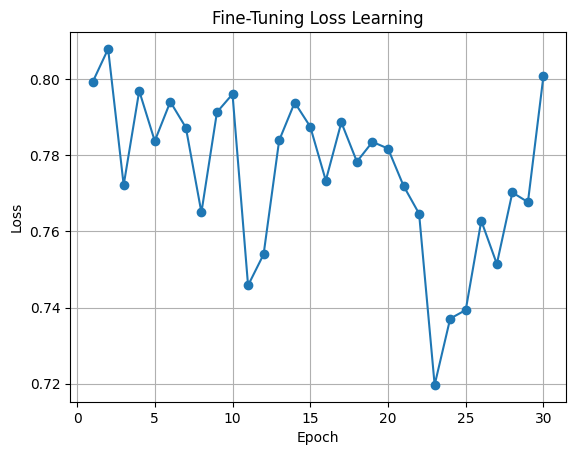

Fine-Tuned Test Accuracy of the model: 50.64%


In [ ]:
import matplotlib.pyplot as plt

train_losses = []
epochs = 30  # Fine-tuning ke liye 10 epochs kaafi hain

for epoch in range(1, epochs + 1):
  model.train()
  running_loss = 0
  correct = 0
  total = 0

  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)

    optimizer.zero_grad()
    prediction = model(images)
    check_loss = criterion(prediction, labels)
    check_loss.backward()
    optimizer.step()

    running_loss += check_loss.item()

    _, predicted = torch.max(prediction.data, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

  # Epoch end par learning rate update hoga
  #scheduler.step()
  current_lr = optimizer.param_groups[0]['lr']

  avg_loss = running_loss / len(train_loader)
  train_accuracy = 100 * correct / total
  train_losses.append(avg_loss)

  print(
      f'Epoch {epoch}/{epochs} ---> Loss: {avg_loss:.4f} | Train Accuracy:'
      f' {train_accuracy:.2f}% | LR: {current_lr:.6f}'
  )

# Graph Plotting
plt.plot(range(1, epochs + 1), train_losses, marker='o')
plt.title('Fine-Tuning Loss Learning')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

# 3. Test Accuracy Check
model.eval()
correct = 0
total = 0

with torch.no_grad():
  for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)
    outputs = model(images)
    _, predicted = torch.max(outputs.data, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total
print(f'Fine-Tuned Test Accuracy of the model: {test_accuracy:.2f}%')